# ESR Support

- winter/spring combo

- productivity and ice at M2

In [97]:
import pandas as pd
import xarray as xr
import datetime
import glob
import numpy as np

In [98]:
import cmocean
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.dates import YearLocator, WeekdayLocator, MonthLocator, DayLocator, HourLocator, DateFormatter
import matplotlib.ticker as ticker

#wrap the plot in image settings for visual appeal
# may be able to make this cleaner or just a preset
%run '../../settings/mpl_plot_settings.py'

<Figure size 640x480 with 0 Axes>

In [99]:
# files = glob.glob('../../moorings/2026/26bs2a/*.nc')
files = glob.glob('/Users/bell/ecoraid/2025/Moorings/25bs2c/final_data_cf/*.nc')
tdf = pd.DataFrame()
for file in files:
    xdf = xr.load_dataset(file)
    df = xdf.to_dataframe()
    df['timeseries_id'] = file.split('/')[-1].split('.nc')[0]

    tdf = pd.concat([tdf,df],axis=0)

files = glob.glob('/Users/bell/ecoraid/2026/Moorings/26bs2a/final_data_cf/*.nc')
tdf_2 = pd.DataFrame()
for file in files:
    xdf = xr.load_dataset(file)
    df = xdf.to_dataframe()
    df['timeseries_id'] = file.split('/')[-1].split('.nc')[0]

    tdf_2 = pd.concat([tdf_2,df],axis=0)

tdf = pd.concat([tdf,tdf_2])

files = glob.glob('/Users/bell/ecoraid/2026/Moorings/26bspr2a/final_data_cf/*.nc')
tdf_2 = pd.DataFrame()
for file in files:
    xdf = xr.load_dataset(file)
    df = xdf.to_dataframe()
    df['timeseries_id'] = file.split('/')[-1].split('.nc')[0]

    tdf_2 = pd.concat([tdf_2,df],axis=0)

tdf = pd.concat([tdf,tdf_2])


1.0
11.0
23.0
45.0


(0.0, 50.0)

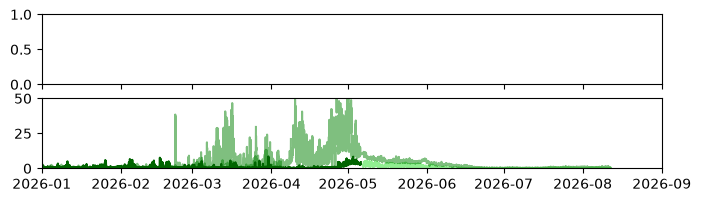

In [120]:
fig, ax = plt.subplots(2,figsize=(8, 2),sharex=True)

for g,gv in tdf.groupby('depth'):
    if gv[~np.isnan(gv.chlor_fluorescence)].empty:
        continue
    print(g)
    if g == 1.0:
        ax[1].plot(gv.index.get_level_values('time'),gv.chlor_fluorescence, 'lightgreen', label='chlorophyll')
    if g == 11.0:
        ax[1].plot(gv.index.get_level_values('time'),gv.chlor_fluorescence, 'green', label='chlorophyll',alpha=.5)
    if g == 23.0:
        ax[1].plot(gv.index.get_level_values('time'),gv.chlor_fluorescence, 'green', label='chlorophyll',alpha=.5)
    if g == 45.0:
        ax[1].plot(gv.index.get_level_values('time'),gv.chlor_fluorescence, 'darkgreen', label='chlorophyll')
        
ax[1].set_xlim([datetime.date(2026,1,1),datetime.date(2026,9,1)])
ax[1].set_ylim([0,50])

In [121]:
icedf = pd.read_csv('/Users/bell/Programs/Python/EcoFOCI_Jupyter_Notebooks/EcoFOCI_Moorings/M2_IntegratedHeat/meaniceinbox_bs2_56.869N_164.05W_50.0km_Box_1978-2026.csv')

for year in icedf.drop(['day_of_year'],axis=1).columns:
    if year == '2026':
        ax[0].plot([datetime.datetime.strptime(f'{year} {x}','%Y %j') for x in icedf.day_of_year], icedf[year],c=(120/255,23/255,154/255),alpha=0.75)
ax[0].set_xlim([datetime.date(2026,1,1),datetime.date(2026,9,1)])

ax[1].xaxis.set_major_locator(DayLocator(bymonthday=1))
ax[1].xaxis.set_minor_locator(DayLocator(bymonthday=15))
ax[1].xaxis.set_minor_formatter(DateFormatter('%b\n%Y'))
ax[1].xaxis.set_major_formatter(DateFormatter(''))
ax[1].xaxis.set_tick_params(which='major', pad=3)
ax[1].xaxis.set_tick_params(which='minor', pad=5)

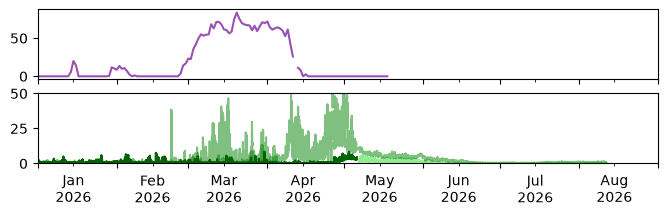

In [122]:
fig

In [103]:
year

'2026'